---

# **Week 6 - Hashing and Evidence Integrity**

---


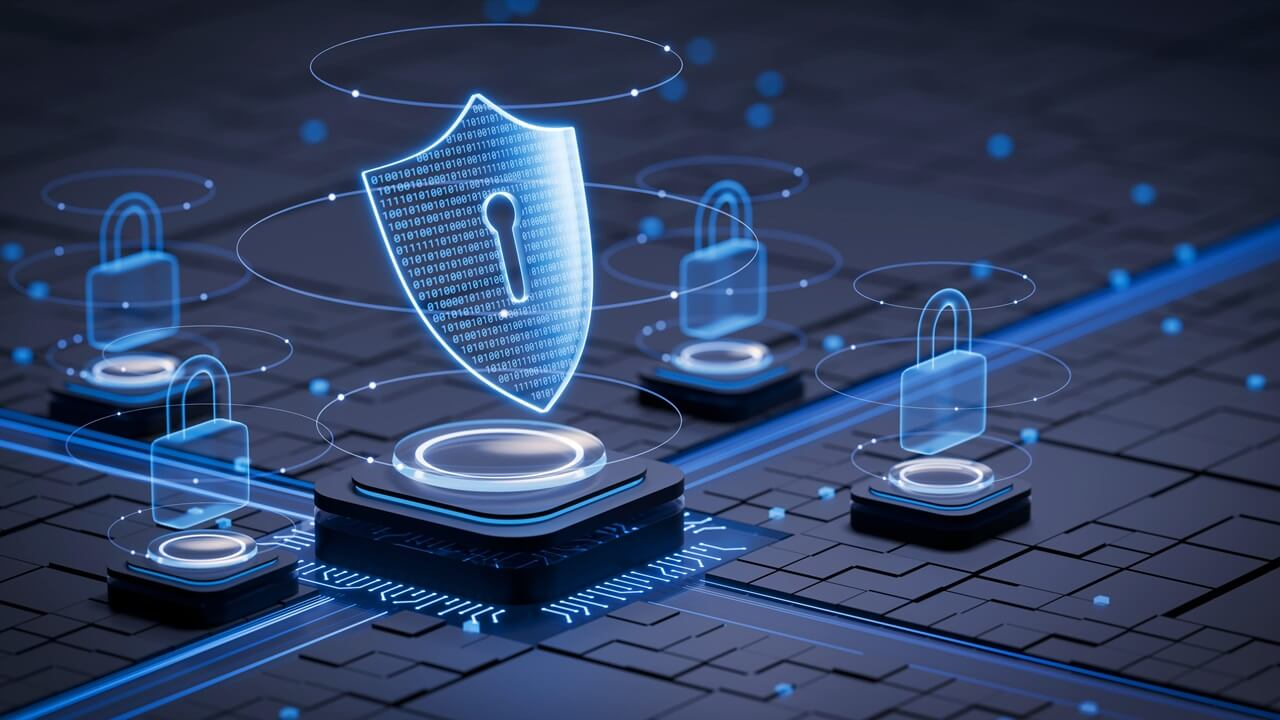


# 👋 **About Me:**

---

**👨‍🏫 Dr. Usama Arshad**
- Assistant Professor, FAST National University, Islamabad  
- PhD in Computer Science - Blockchain & AI, Ghulam Ishaq Khan Institute  
- Research Assistant - National Yunlin University, Taiwan (AI in Healthcare)  
- President - Graduate Students Society, GIKI  
- Published Author - IEEE, Springer, Elsevier (Blockchain, AI, Cybersecurity)  
- GitHub: [github.com/usamajanjua9](https://github.com/usamajanjua9)  
- LinkedIn: [linkedin.com/in/usamajanjua9](https://linkedin.com/in/usamajanjua9)  
- Website: [usamajanjua.com](https://usamajanjua.com)


## 📚 Lecture guide

* **[Lecture 16](#lecture-16):** Integrity, cryptographic hashes and SHA-256.
* **[Lecture 17](#lecture-17):** Baselines, working copies, re-checks and mismatch causes.
* **[Lecture 18](#lecture-18):** Hash manifests; hashing versus encryption.


<img src="assets/gifs/week_06_concept.gif" width="960" alt="Hash comparison depends on a baseline. Identify bytes: Specify the exact file, stream, or ordered image segments. Hash: Record the algorithm and digest with a trusted baseline. Compare: Recompute using the same algorithm over the same scope. Interpret: A match supports unchanged bytes; it does not establish authorship.">


---

<a id="lecture-16"></a>

## 🔹 Lecture 16: Integrity, cryptographic hashes and SHA-256

<img src="assets/gifs/3ohzAjw1ZQl5QpfXnG.gif" width="350" alt="illustration">

### Learning Objectives

* Describe input bytes, digest length, determinism and collision resistance.
* Compute and interpret a SHA-256 digest without treating it as an identity or truth guarantee.
* Explain why a small content change can produce a different digest.

---


### **1. Evidence Integrity**

---

**Integrity**, in the digital-forensic sense, is the property that evidence is *unchanged* from a defined reference state. It is a narrow and testable property, and it needs to be kept distinct from three neighbouring concepts that are often confused with it.

**Authenticity** is the question of whether evidence is what it purports to be: that the email really came from the person named, that the photograph really depicts the scene at the claimed time: **Provenance** is the documented history of where evidence came from and who handled it: **Confidentiality** is whether unauthorised persons can read it. Integrity is none of these. A forged document whose bytes have not changed since it was forged has perfect integrity and no authenticity; a genuine document altered after seizure has authenticity at origin and has lost integrity.

Integrity matters in three moments of an investigation. At **acquisition**, to show the copy equals what was read (Week 5). During **handling and storage**, to show nothing has changed while evidence sat in a cabinet or was moved between labs. At **presentation**, to show that what is being relied upon in a report or in court is the same content as what was acquired. The logical structure is always the same: a *reference state* is fixed at some moment by recording a short fingerprint of the content, and a later *comparison* tests whether the content still has that fingerprint. This is why an integrity method has to satisfy two requirements: a fingerprint that is **sensitive** (any change alters it) and **compact** (a few dozen characters can be recorded in a report, a custody form or a ledger).

Inspection cannot fill this role. No human can compare two 500 GB images byte by byte by eye, and even automated byte comparison requires both copies to be present in the same place, which defeats the purpose of verifying a copy against an original that may no longer be available. A hash lets the reference state travel as a few characters while the evidence itself stays where it is.


### **2. Cryptographic Hash Functions**

---

A **hash function** is a function $H$ that maps an input of arbitrary length to an output of fixed length:

$$H : \{0,1\}^{*} \longrightarrow \{0,1\}^{n}$$

A **cryptographic hash function** is a hash function with additional security properties that make the output a trustworthy fingerprint even in the presence of an adversary. Ordinary (non-cryptographic) hash functions - those used in hash tables or simple checksums like CRC32 - are designed to be fast and to spread data evenly, and are good at detecting *accidental* errors; but they can be defeated trivially by someone who wants to change data without changing the checksum, so they are unsuitable as evidence-integrity fingerprints.

The properties are best learned one at a time, each with its own demonstration. The Python lab uses Python's standard `hashlib` library, which implements the standard algorithms and is the same library that forensic scripts rely on.


### **3. Input**

The **input** (also called the *message*) is any sequence of bytes: a one-byte file, a document, a 500 GB disk image. The hash function does not "understand" the input; it processes bytes, so the same text saved in two encodings (UTF-8 versus UTF-16) is different input and produces different digests. The **digest** (or *hash value*, *fingerprint*) is the fixed-length output, usually displayed in hexadecimal. A SHA-256 digest is 256 bits = 32 bytes = 64 hexadecimal characters.

Because the output is far smaller than most inputs, many different inputs *must* map to each digest (the pigeonhole principle). Hashing is therefore **lossy**: you cannot recover the input from the digest, and different inputs can in principle collide. The security of a hash function lies in making such coincidences computationally impossible to find on purpose, not in preventing them from existing.


**Forensic Significance.** Known-answer vectors are the hashing analogue of tool validation in Week 5: before trusting a script, confirm it reproduces published results. The encoding example is a reminder that a hash describes *bytes*, not "what the text says" - which is why identical-looking documents can have different hashes.


### **4. Digest**

The **digest** (hash value) is the fixed-length output of a hash function for a given input. Examiners record it in a canonical hex form together with the algorithm name.


### **5. Deterministic Output**

A hash function is **deterministic**: the same input always yields the same digest, on every computer, in every programming language, at any time. Determinism is what makes a hash recorded in 2026 comparable with a hash computed in 2036 by a different examiner using different software. It also means the hash carries **no randomness, no timestamp and no secret**: anyone who has the input can compute the digest. That is a strength (anyone can verify) and a limitation (anyone can *recompute*, including someone who has modified the evidence).


### **6. Fixed-Length Output**

Whatever the input size - zero bytes, one byte or a terabyte - the digest has the same length for a given algorithm. A hash therefore reveals **nothing about the size of the input** (the examiner must record the size separately, as manifests do in this section). The compactness makes hashes practical to record and compare, but it is also why they are not an index of content: two digests that look similar (sharing many leading characters) say nothing about similarity of the inputs - which leads directly to the avalanche property.


**Forensic Significance.** Even "nothing" has a digest, so a hash of an empty file proves only that the file was empty. And because the length is constant, the digest cannot be used to infer anything about input size: size is separate metadata that a manifest must carry.


### **7. Avalanche Effect**

The **avalanche effect** is the requirement that a tiny change to the input - flipping a single bit - should change roughly **half** of the output bits, in an unpredictable pattern. For an $n$-bit digest the expected number of differing bits is $n/2$, with standard deviation $\sqrt{n}/2$; for SHA-256 that is 128 bits $\pm$ 8. Avalanche is what makes tampering detectable: there is no such thing as a "small" modification that yields a "nearly equal" digest, and no way to find out how close an altered file is to the original from the digests alone. A **checksum** such as the sum of the bytes, by contrast, changes only slightly with small edits and is unchanged by rearrangements.


**Forensic Significance.** Avalanche is the reason a one-character alteration of a financial figure cannot hide. The checksum contrast explains why simple checksums are rejected for evidence: they miss rearrangements and give a false sense of safety.


### **8. Collision Resistance**

Security of a cryptographic hash is usually stated as three distinct resistance properties, each requiring a different amount of attacker work:

- **Preimage resistance:** given a digest $y$, it is infeasible to find *any* input $x$ with $H(x) = y$. Generic work: about $2^{n}$ evaluations.
- **Second-preimage resistance:** given an input $x$, it is infeasible to find a *different* input $x' \neq x$ with $H(x') = H(x)$. Generic work: about $2^{n}$ evaluations. This is the property that protects an *existing* exhibit against substitution.
- **Collision resistance:** it is infeasible to find *any* two distinct inputs $x \neq x'$ with $H(x) = H(x')$. Because the attacker chooses both, the **birthday paradox** applies: a collision is expected after roughly $\sqrt{\pi/2}\cdot 2^{n/2} \approx 1.25 \times 2^{n/2}$ evaluations.

$$P(\text{collision after } k \text{ hashes}) \approx 1 - e^{-k^{2}/2^{\,n+1}}$$

Collision resistance is therefore the *weakest* of the three: an $n$-bit hash offers only about $n/2$ bits of collision security. For a 128-bit hash like MD5 the generic bound is $2^{64}$, which is already within reach of well-resourced attackers, and cryptanalytic shortcuts have reduced the real cost far below even that. For SHA-256 the generic bound is $2^{128}$, which is out of reach.

For forensics the distinction matters in two ways. A collision attack requires the attacker to *prepare both files in advance* (for example a harmless and a harmful document with the same MD5), so it threatens situations where one party controls the creation of the evidence; it does not by itself let an attacker alter an existing exhibit to match a recorded hash (that would require a second-preimage attack, which remains infeasible even against MD5 and SHA-1).


**Forensic Significance.** A 256-bit digest has the same structure at vastly larger scale: collisions about $2^{128}$ and preimages about $2^{256}$ trials. The different generic work factors explain why a collision search can succeed before a preimage search, and why the thing that protects an *already existing* exhibit is second-preimage resistance.

An opposing expert says, "Two different files can have the same MD5 hash, so an MD5 match proves nothing." Another says, "MD5 collisions need both files to be crafted in advance; a match between the seized file and the copy still strongly shows they are the same." Which statement is more accurate for an ordinary non-adversarial case, and what additional fact would change your answer?

<details><summary>Show model answer</summary>

For an ordinary case where no one is believed to have prepared a colliding pair, the second statement is closer to the truth: a match shows the content is the same *unless* an adversary engineered a collision, which requires control over how the exhibit was created. The first statement is true in principle but overstated. The answer changes if there is reason to suspect that a party had the opportunity to craft the files (for example the party created the original document) - then MD5 alone is insufficient and a collision-resistant algorithm (SHA-256) should be used for the comparison.
</details>


### **9. Common Hash Algorithms**

---

Four algorithm families dominate forensic practice. They differ in output size, internal structure and, critically, in the *state of public cryptanalysis*.

Each entry carries one or more **hash values**, and each value is labelled with its **algorithm**. The header states which algorithms the manifest uses. The reasons are those of this section: a bare digest is ambiguous, algorithms age, and recording a modern primary (SHA-256) plus an optional legacy value (MD5) preserves both strength and compatibility. When algorithms are later added or retired, the manifest records *when* each digest was computed, rather than silently replacing earlier ones.

A manifest is the bridge between Week 5 and the rest of the course. The image segments and logs from an acquisition become entries; the acquisition report's hash becomes the manifest's reference for the image; and every later analysis export is added to a *new, dated* manifest instead of editing the old one.


### **10. MD5**

**MD5** (Message-Digest Algorithm 5, 1992) produces a **128-bit** digest, processing the input in 512-bit blocks. For many years it was the default hash in forensic tools, and it remains embedded in tool output, older reports and reference databases. Its collision resistance is **broken**: practical collision attacks were published in 2004, chosen-prefix collisions followed, and they were reportedly used in malware to forge a code-signing certificate (the Flame malware, 2012). Collisions can now be produced in seconds on ordinary hardware. Preimage and second-preimage attacks on MD5 remain computationally impractical, which is why MD5 can still detect *accidental* corruption reliably and why it is still seen as acceptable for non-adversarial uses such as matching against legacy reference sets. It should not be the only algorithm used where an adversary might have influenced how the evidence was created.


### **11. SHA-1**

**SHA-1** (1995) produces a **160-bit** digest and was long regarded as the stronger successor to MD5. Theoretical weaknesses were found in 2005, and in 2017 researchers published the first practical collision (the "SHAttered" attack), later followed by cheaper chosen-prefix collisions. Standards bodies have deprecated SHA-1 for digital signatures and encourage migration. Like MD5, SHA-1 remains widely encountered in forensic tools and reference hash sets, and as a second algorithm it provides compatibility, but it is considered **legacy** for any integrity claim where adversarial manipulation is conceivable.


### **12. SHA-256**

**SHA-256** belongs to the **SHA-2** family (2001). It produces a **256-bit** digest using 32-bit words, 512-bit blocks and 64 rounds of mixing, in a Merkle-Damgård construction: the input is padded (including its length), split into blocks, and each block is folded into a running internal state, which is output at the end. No practical collision, preimage or second-preimage attack on SHA-256 is known, and its generic collision bound of $2^{128}$ is far beyond feasible computation. It is the **current default** for forensic integrity and the algorithm recommended as the *primary* hash in this course. One structural note: because plain SHA-256 outputs its full internal state, an attacker who knows $H(m)$ and the length of $m$ can compute $H(m \| \text{padding} \| m')$ without knowing $m$ - the *length-extension* property. It does not endanger evidence-integrity use (where the examiner hashes known data) but is why $H(\text{key} \,\|\, m)$ must never be used as a message-authentication code; HMAC is used instead.


### **13. SHA-512**

**SHA-512** is the large sibling of SHA-256: **512-bit** digest, 64-bit words, 1,024-bit blocks and 80 rounds. It offers a bigger security margin on paper (collision bound $2^{256}$), and on many 64-bit processors it hashes large inputs faster than SHA-256 because it processes more data per round. The cost is a longer digest (128 hexadecimal characters) that is clumsier to transcribe into a report. In practice SHA-256 already exceeds any realistic security need for evidence integrity, so the choice between them is usually driven by tool support, organisational standard and performance.


### **14. Legacy and Modern**

The distinction between **legacy** and **modern** algorithms is not "old versus new" but "what an adversary can do". The practical rules are:

| Algorithm | Digest | Status of collision resistance | Appropriate forensic use |
|---|---:|---|---|
| MD5 | 128 bits | Broken (practical collisions) | Detect accidental corruption; match legacy reference sets; *secondary* algorithm only |
| SHA-1 | 160 bits | Broken in practice (public collisions) | Same as MD5; legacy compatibility; deprecated for new integrity claims |
| SHA-256 | 256 bits | No known practical attack | **Primary** algorithm for acquisition, manifests, reports |
| SHA-512 | 512 bits | No known practical attack | Alternative primary where required; fast on 64-bit CPUs |

A sensible policy is **dual hashing with a modern primary**: record SHA-256 (or SHA-512) as the authoritative value, and optionally MD5 or SHA-1 alongside it for compatibility with older tools and databases. Two *different* algorithms being equal is stronger than either alone, because forging both simultaneously is harder than forging the weaker one. Whatever is chosen, record the algorithm name beside every digest: a bare hex string is ambiguous, although its length hints at the algorithm (32, 40, 64 or 128 hex characters).

**Note.** Do not "upgrade" old evidence by re-hashing and discarding the original hash. Keep the legacy value that was recorded at acquisition, add the new algorithm's digest with the date it was computed, and state in the report which was recorded when. A newly computed SHA-256 shows today's content, not the state at the time MD5 was originally recorded.


### Lecture 16: Knowledge Check

**Question:** Does hashing hide the evidence?

**✅ Reasoned answer:** No. Hashing derives a digest; it does not encrypt the input.

**Apply the method.** A SHA-256 digest contains 64 hexadecimal characters. How many bytes does that represent, and can it reveal the file size?

<details><summary>Show the reasoned answer</summary>

Each hexadecimal character represents four bits: 64 × 4 = 256 bits = 32 bytes. The fixed digest length does not reveal the input length.

</details>


---

<a id="lecture-17"></a>

## 🔹 Lecture 17: Baselines, working copies, re-checks and mismatch causes

<img src="assets/gifs/d3snVrsKu01KkHknfc.gif" width="350" alt="illustration">

### Learning Objectives

* Establish a documented baseline and distinguish it from working derivatives.
* Choose when to re-check integrity during handling and analysis.
* Investigate mismatches without assuming deliberate alteration.

---


### **1. Forensic Hashing**

---

Hashing is applied at different granularities, and each answers a different question. The **file hash** fingerprints the content of one file. The **image hash** fingerprints the entire contents of an acquired device image - the concatenated stream of every sector (Week 5). The **segment hash** fingerprints one segment file of a segmented image. The same algorithm is used throughout; what differs is the *scope* of the bytes fed into it, and a clear record of scope is as necessary as the digest itself.


### **2. File Hashes**

A **file hash** covers the *content* of the file - the bytes that would be read from beginning to end - and nothing else. It does **not** include the file's name, path, timestamps, permissions, owner or other metadata, which live in the file-system record (Week 4), not in the file. Consequently renaming a file, moving it, or changing its modification time leaves its hash unchanged, whereas adding one byte at the end changes it completely. This is a feature when the aim is to recognise *content* wherever it appears (identifying known files, finding duplicates) and a limitation when the aim is to prove that *the file as stored in a particular place with particular metadata* is unchanged: for that, metadata must be recorded separately and hashed independently, as manifests do.

The practical consequence for file-system evidence (Week 4) is that **a file hash and a file's timestamps are independent pieces of evidence**. Two copies of a document with identical hashes can have different created, modified and accessed times; those times, not the hash, carry the history of handling. Record both - and never use one to vouch for the other.


### **3. Image Hashes**

An **image hash** covers every byte of the acquired image, in order. It therefore detects any change to any sector, including changes in unallocated space that no file-level view would reveal. Three practical points apply. The hash must be computed over the **complete logical stream** - for a segmented image, over the concatenation of segments in order, not over any single segment. The **scope must be stated**: whole device, a single volume, or a readable range with certain sectors excluded. And because images are large, hashing must be **streamed** in chunks so the entire image never has to fit in memory (this section).


### **4. Baseline**

The **baseline hash** (also *reference* or *acquisition* hash) is the digest recorded when the evidence is first captured or received: the reference state against which later comparison is made. A **verification hash** is computed at a later time to test whether the evidence still has the baseline digest. Together they form the basic integrity test:

$$\text{Integrity supported} \iff H(\text{evidence}_{\text{now}}) = H(\text{evidence}_{\text{baseline}})$$

Three conditions make the test meaningful: the baseline must have been computed *before* any opportunity for unwanted change (ideally during acquisition itself), the baseline value must be **recorded in a place whose custodian is independent of whoever might benefit from a change**, and both computations must use the **same algorithm over the same scope**. If any condition fails, the test can pass or fail for reasons unrelated to the integrity of the evidence.


### **5. Verification**

**Verification** recomputes a digest under the same algorithm and scope and compares it to a previously recorded baseline.


### **6. Interpreting Hash Results**

---

Hash results are observations. Interpretation depends on algorithm identity, byte scope, and the independence of the reference value.


### **7. Interpreting Matching Hashes**

A **match** - the verification digest equals the baseline - supports the conclusion that the content now is *the same content* as when the baseline was computed (with the extremely high confidence given by the algorithm's collision and second-preimage resistance). It says nothing about the content between the two moments, nor about the baseline's own correctness.

A **mismatch** is more informative than it first appears, because it must be *explained*, not just reported. A mismatch means that **either the content differs or the comparison was not like-for-like**. Before concluding that evidence was altered, the examiner rules out comparison errors: a different algorithm, a different scope (a segment instead of the whole image; the image including versus excluding fill sectors), a transcription error (a character mistyped in a report), a case or whitespace difference in the recorded string, or hashing a different file. Only when the comparison is shown to be like-for-like is the mismatch attributed to a change in content, and then the next questions concern *where* it changed (per-segment or per-block hashes help) and *how* (accidental corruption in transfer or storage, versus deliberate modification) - which the hash itself cannot answer.

**Process map**

| From | Relationship or condition | To |
| --- | --- | --- |
| Mismatch observed | leads to | Same algorithm? |
| Same algorithm? | No | Recompute with correct algorithm |
| Same algorithm? | Yes | Same scope and same file? |
| Same scope and same file? | No | Align scope: file, segment, image range |
| Same scope and same file? | Yes | Recorded string transcribed correctly? |
| Recorded string transcribed correctly? | No | Correct for case, whitespace, typos |
| Recorded string transcribed correctly? | Yes | Content differs |
| Content differs | leads to | Localise: block/segment hashes |
| Localise: block/segment hashes | leads to | Attribute cause using logs, custody, transfer records |


### **8. Investigating Hash Mismatches**

A **mismatch** means the hashed bytes differ from the reference, or that algorithm/scope/path is not comparable. Triage before alleging tampering.


### **9. What a Hash Match Establishes**

Precision about the limits of hashing is as much a professional skill as computing the hash. The table separates what a *properly computed and independently recorded* hash can support from what it cannot.

| A matching hash **does** support | A matching hash does **not** establish |
|---|---|
| The content now is identical to the content that produced the baseline digest | That the content is **authentic** (genuinely what it claims to be) |
| No change - accidental or deliberate - occurred to the hashed bytes since the baseline (given a trustworthy baseline) | That the content was unaltered **before** the baseline was computed |
| Two copies are the same content, wherever they are held | **Who** created, modified or possessed the content, or **when** it was created |
| A copy made for analysis faithfully represents the master | That the **hash value itself** has not been replaced (unless independently protected) |
| Content identity regardless of name, path or timestamps | That **metadata** (names, paths, timestamps, permissions) is unchanged - metadata is not part of a file hash |
| An identified file matches a known reference file | That the content is **relevant, lawful, or innocent**, or that the user knew it was there |

Two further limits deserve emphasis. First, a hash cannot show *how much* two non-matching items differ: avalanche destroys all similarity information (similarity hashing and fuzzy hashing are different tools, outside this course). Second, a hash is evidence about *bytes*, so statements like "this is the same photograph" are about content identity of the file, not about whether two different images - a re-saved copy, a resized copy - depict the same scene.

**Note.** Phrases to avoid in reports: "the hash proves the evidence is authentic", "the hash proves nothing was tampered with" (without qualification), and "the hash identifies the suspect's file" (it identifies *content*). Prefer: "the SHA-256 digest of the file, computed on <date> using <tool>, matches the baseline digest recorded at acquisition on <date>, which indicates the content is unchanged since that time."


### **10. What a Hash Match Cannot Establish**

A hash match does **not** prove authenticity, authorship, intent, or correct original seizure. Custody and documentation still matter.


### **11. Practical Hashing**

---

In this practical we hash synthetic evidence files and a small synthetic image **in a temporary directory**, using streaming reads, and test which changes affect the hash and which do not. All data is invented.

Before running the cell, predict for each of the six operations (copy, rename, change modification time, append one byte, change one character, change line endings) whether the SHA-256 digest will change. Record your predictions, then compare.


**Forensic Significance.** The pattern encodes the rule: a hash tracks **content bytes only**. Metadata can change without affecting it, and invisible differences such as a trailing space or line-ending convention change it completely. The ordered-segment example illustrates the Week 5 point that the evidence is the *ordered stream*.


**Forensic Significance.** The function operationalises the mismatch triage: it separates comparison problems (formatting, algorithm, transcription) from genuine content mismatch. Note the last-but-one case: a one-character transcription error produces the *same output* as a tampered file, which is why a mismatch must be investigated, not assumed to mean tampering.


### **12. Modification Detection Exercise**

---

**Protect the baseline as well as the file.** Consider these three states:

| Evidence file | Recorded baseline | Comparison | Meaning |
| --- | --- | --- | --- |
| Original bytes | Independently retained original digest | Match | Bytes match the baseline at this check |
| Changed bytes | Original digest | Mismatch | A content difference is detected |
| Changed bytes | Digest replaced to match the change | Match against the replaced value | The compromised record conceals the difference |

An independent register or appropriately protected authenticated record helps preserve the reference. A keyed authentication code depends on protecting its key. A hash chain can reveal changes only when a trustworthy checkpoint is retained; someone who can rewrite the entire chain and its reference can recompute it. None of these controls replaces custody records.

A regional forensic laboratory (Lab A) images a seized laptop and records, in its acquisition report, a SHA-256 digest for the image `EV-0113.dd` (size 512,110,190,592 bytes). The image is copied to an external drive and sent by courier to a partner laboratory (Lab B) for a specialised review. Lab B computes a SHA-256 digest and reports that it **does not match** the recorded value. The partner's manager emails: *"Your image has been tampered with."* Lab A retains the master image in its secure store.

*(Synthetic scenario for teaching; all identifiers are invented.)*

**Forensic reasoning chain**

- **Observation (O).** Lab A's report records SHA-256 value $h_A$ and size 512,110,190,592 bytes. Lab B's computed digest $h_B \neq h_A$. Lab B's file size is also 512,110,190,592 bytes. Lab B used SHA-256 (64 hex characters) and hashed the single file `EV-0113.dd`. Per-block hashes (1 MiB blocks), when compared, show that exactly one block differs. Lab A re-hashes its retained master and obtains $h_A$ again.
- **Interpretation (I).** The comparison is like-for-like (same algorithm, same file, same size, digests transcribed correctly), so the transmitted copy has different content from the master. Equal size and one differing block indicate a localized difference. Confirm object identity separately; neither fact identifies the cause. Lab A's master still has digest $h_A$, so the master is unchanged since acquisition.
- **Corroboration (C).** The courier record notes that the external drive was read once at Lab A for copying and its file system reported a write error that was retried. A fresh copy from the master to a new drive produces a file whose digest equals $h_A$ in Lab B's recomputation. A single-block difference is consistent with a transfer or storage fault, and no log shows any other access to the image.
- **Conclusion.** The delivered copy differs from the retained master in one 1 MiB region; the master image is intact and has been verified against its recorded baseline. The statement "tampered with" is unsupported: the evidence shows a *difference in content of the delivered copy*, caused most plausibly by a transfer fault, and shows that the master is unaffected. Lab B should use the freshly copied, verified file.
- **Limitation.** The hash comparison shows *that* and (with block hashes) *where* the delivered copy differs; it cannot distinguish accidental corruption from deliberate modification of that block. The attribution to a transfer fault rests on the corroborating logs and the clean re-copy, not on the hash. The corrupted copy should be retained and documented, not deleted, so that the cause can be examined further if needed.

**Discussion.** Lab B's manager says: "Block 41,877 differs, so the data at that block was changed by someone who knew what they were doing." Write a short rebuttal that (a) uses the avalanche property, (b) explains why the *size* of the difference says nothing about intent, and (c) names two records that would help assess cause.

<details><summary>Show model answer</summary>

(a) Because of avalanche, a one-bit error and a deliberate edit produce equally unrelated digests; the digest cannot show how much or how cleverly something changed. (b) A localised mismatch can arise from a failing connector or a flipped bit in storage as readily as from editing; the hash difference carries no information about intent. (c) The transfer/copy logs from the external drive (errors, retries), the custody and access records for the drive, and a verification of the freshly re-copied file against the master baseline.
</details>

Work through these after the practical and before opening the answers.

**Extension: two algorithms in one pass.** Write a function that streams a file once and returns both its MD5 and SHA-256 digests (feed each chunk to *both* hash objects). Test it on `exhibit_notes.txt`-style content from the practical and verify that each digest equals the one computed by a separate single-algorithm pass. Explain why computing both in one pass matters for a large image.

<details><summary>Show model answer sketch</summary>

```python
import hashlib

def dual_hash(path, chunk=1 << 20):
    md5, sha = hashlib.md5(), hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            md5.update(block)
            sha.update(block)
    return md5.hexdigest(), sha.hexdigest()
```
One pass reads the input once instead of twice, and guarantees both digests were computed over exactly the same bytes as read.
</details>

**Reflection: what a later hash match establishes.**

A colleague says: "I re-hashed the evidence after the case ended and got a match, so the evidence was never altered while it was in storage." What is the logical gap in that sentence, and what could you say that is *accurate*?

<details><summary>Show model answer</summary>

A match at the end shows the content now equals the baseline; it does not show that nothing happened in between *if* the match is with a baseline that the same person controlled, nor does it test the baseline's own origin. What can be said: "The content at <date> has the same SHA-256 digest as recorded at acquisition on <date> in an independent register; the bytes currently match that recorded baseline. This check does not establish the entire history between the two measurements." The accuracy of the first part rests on the baseline's independence and on a match of both endpoints; any intermediate change that was undone would be invisible to hashing.
</details>

**Exercise: an invisible difference.** Two examiners hash "the same" 3-line text file and get different SHA-256 values. Neither altered it. List four *non-malicious* reasons (hint: think about line endings, encodings, a byte-order mark, trailing whitespace and transfer modes) and how you would test each with a single command or line of code.

<details><summary>Show model answer</summary>

(1) CRLF vs LF line endings - compare bytes for `b"\r\n"`. (2) Different text encoding or a UTF-8 BOM (`b"\xef\xbb\xbf"` at the start) - inspect the first bytes. (3) Trailing whitespace or a final newline added by an editor - compare file sizes and the last bytes. (4) A text-mode transfer (FTP ASCII mode) or an editor re-saving the file - compare against a hash taken before the transfer. In each case compare sizes first and then bytes with a hex dump.
</details>

These activities extend the practical. Attempt them with the code you have, then review the model answers.

**Extension: identify possible substitutions.** Extend the lab's verification loop to flag a changed file whose current SHA-256 matches another file's baseline digest. Use only a disposable copy of the training collection. Replace one training file's contents with another file's contents, then compare against the original manifest.

<details><summary>Show the reasoning</summary>

Build a lookup from each baseline digest to a **list** of matching paths, because several baseline files may have identical content. When a file fails its own baseline comparison, look for its new digest in that lookup. Report all matching candidate paths and preserve the original mismatch. The result suggests a content substitution; hashes alone do not establish who performed it or which duplicate supplied the bytes.

</details>

**Reflection: duplicate content and rename ambiguity.**

Your verifier reports a *missing* file and an *unexpected* file with the same hash, but the manifest contains **two** entries with that hash (a duplicate group). Why is the rename inference now ambiguous, and what should the report say?

<details><summary>Show model answer</summary>

With duplicates, either copy could be the one that moved, or one copy could have been deleted and another created from the remaining one. The identical content cannot distinguish these. The report should state "content identical to a missing entry that has a duplicate in the manifest; the movement of a specific copy cannot be determined from hashes", and recommend consulting access logs and the custody record.
</details>

**Exercise: what the manifest cannot detect.** List four kinds of change to a collection that a content-hash manifest like the one built here would **not** detect, and for each say what additional information the manifest would need to detect it.

<details><summary>Show model answer</summary>

(1) Timestamp or permission changes - add timestamps, mode bits and owner to each entry. (2) Changes to empty folders or the directory structure - record directories as entries. (3) Alternate data streams or extended attributes - hash/record them or use a container format. (4) Changes made *before* the manifest was created - require an earlier baseline (acquisition hash) and the custody record. A fifth: replacement of the verifier script or the manifest itself - hash both and keep the references in an independent register.
</details>


### Lecture 17: Knowledge Check

**Question:** Does a mismatch prove deliberate tampering?

**✅ Reasoned answer:** No. Confirm algorithm, byte scope and source identity, then investigate changes or errors.

**Apply the method.** A transferred image has the same size as the master but a different SHA-256. Name the first checks before deciding the cause.

<details><summary>Show the reasoned answer</summary>

Confirm source and destination identity, algorithm, exact byte scope, digest transcription, and complete reads. Recheck the protected master and transfer logs. Equal size does not exclude changed bytes; mismatch does not establish intent.

</details>


---

<a id="lecture-18"></a>

## 🔹 Lecture 18: Hash manifests; hashing versus encryption

<img src="assets/gifs/3ohzAjw1ZQl5QpfXnG.gif" width="350" alt="illustration">

### Learning Objectives

* Build a manifest that links paths, sizes, algorithms and digests.
* Classify missing, modified, unexpected and duplicate objects.
* Distinguish hashing, encryption and authentication.

---


### **1. Evidence Collections**

---

An **evidence collection** is the set of digital items belonging to a case or an exhibit, stored together and managed as a unit. Its members are of several kinds: *primary evidence* (image segments, exported data), *derived material* (extracted files, carved objects, parsed artefacts and reports generated from them), *records of the process* (acquisition logs, tool outputs, verification reports) and *administrative documents* (custody forms, authorisations). They have different integrity requirements: primary evidence must never change; derived material may be regenerated but its provenance must be traceable; process records should be frozen once complete.

A collection has **structure**: a folder hierarchy, naming conventions and evidence identifiers that link items to exhibits (for example `EV-0001` for the laptop image and `EV-0002` for a USB drive). That structure carries meaning - a file's location within a collection helps to say what it is - so the structure itself is part of what must remain intact. Structure also creates the characteristic risks of collections that do not arise for single files: items can be **lost** (a missing segment), **added** (an unlogged export dropped into an evidence folder), **replaced** (a different file with the same name), **renamed or moved**, or **duplicated**. A set of per-file hashes without a complete list of what *should* be present cannot detect the first two risks; this is exactly what a manifest adds.


### **2. Integrity Manifests**

---

An **integrity manifest** is a structured, human- and machine-readable record that lists the items of an evidence collection with the attributes needed for later verification. It is created at a defined moment (for example on receipt or at the close of acquisition), by a named person or process, and it becomes the **reference state** for the collection - the multi-item equivalent of the baseline hash of this section.

A manifest should be:

- **Complete** - listing every item in scope, with scope stated (root folder, inclusions and exclusions).
- **Precise** - each entry unambiguous about *which* item it refers to and *which* algorithm produced each hash.
- **Self-describing** - recording the case, creation date, creator, tool and version, hash algorithms, path convention and schema version.
- **Protected** - the manifest is evidence about the collection, so it must itself be fingerprinted (its own hash) and the fingerprint kept somewhere independent, otherwise an alteration can be hidden by editing the manifest to match (the lesson of the tampering demonstration).
- **Stable** - written in a canonical form (sorted entries, fixed key order, defined encoding) so that regenerating it from the same collection yields byte-identical output and therefore the same manifest hash.

Common practical formats are plain-text hash lists (`sha256sum`-style lines of digest and path), CSV, JSON, and the BagIt format used in digital preservation. The simplest hash lists lack sizes, evidence IDs and algorithm names; JSON or CSV manifests with explicit fields are preferable for casework.

**Process map**

| From | Relationship or condition | To |
| --- | --- | --- |
| Manifest | leads to | Header: case, created, creator, tool, algorithms, schema, root label |
| Manifest | leads to | Entries |
| Entries | leads to | Evidence ID |
| Entries | leads to | Normalised relative path |
| Entries | leads to | Size in bytes |
| Entries | leads to | Hash per algorithm |
| Manifest | leads to | Manifest's own hash; recorded independently |


### **3. Evidence Identifiers**

The **evidence ID** ties each manifest entry to the exhibit (and thus to the chain of custody) from which it derives. Paths and file names are poor identifiers because they are chosen by people, change between systems, and say nothing about provenance. An evidence ID such as `EV-0002` is assigned by the examiner's evidence register, is unique within the case, never reused, and appears both in the manifest and in the physical or logical labelling of the exhibit. Several manifest entries share an evidence ID (an image has many segments), and the ID is the key that links the manifest to the custody and acquisition records of Weeks 3 and 5. An item with no evidence ID is an anomaly to be explained.


### **4. Recording File Paths**

The **path** records where, within the collection, the item lives. It should be stored **relative to a stated root** (for example `EV-0002_usb/files/photos/img001.bin`) rather than as an absolute path such as `D:\Cases\2026\..` that is meaningless on another machine. The path is the item's *location identity*: two entries with the same hash but different paths are two distinct items that happen to have identical content, and one entry whose path has changed is, from the manifest's perspective, a missing item together with an unexpected item - a distinction we exploit in verification to detect probable renames.


### **5. Recording File Sizes**

The **size** in bytes is a cheap, fast and independent check. It is useful in three ways: it can reveal truncation or growth without computing any hash (a size mismatch is conclusive that content changed); it lets a verification process **skip hashing** only when a conservative policy allows (generally it should not, since a modification can preserve the size, as the practical will show); and it supports reconciliation with other records (for example sectors × sector size for an image Size must always be recorded in exact bytes, never in rounded human-readable units.


### **6. Algorithm**

Record the **algorithm** explicitly in every manifest entry and report. Never infer the algorithm only from digest length.


### **7. Recording Algorithms and Digests**

Store the **hash** (digest) in canonical lowercase hex (or another declared encoding) and protect the manifest that holds it.


### **8. Path Identity**

---

**Path Identity.** Define the term precisely, tie it to observable artifacts, and state what a finding supports and what it does not establish.


### **9. Relative Paths**

**Relative paths** from a declared collection root remain meaningful when evidence is moved between systems.


### **10. Absolute Paths**

**Absolute paths** break across machines, drive letters, and mount points; avoid them as primary manifest identity.


### **11. Normalization Without Losing Path Identity**

Preserve the original path exactly as acquired. If a tool also creates a comparison key, retain both values and document the transformation. A path is interpreted under a particular file system and API: case sensitivity, Unicode equivalence, separators, and trailing-character behavior vary.

| Issue | Example | Appropriate handling |
| --- | --- | --- |
| Separators | `photos\img001.bin` versus `photos/img001.bin` | Interpret according to the source convention; a backslash can be a literal character on another system |
| Case | `Report.txt` versus `report.txt` | Do not merge without confirming source semantics; preserve separate records when ambiguous |
| Unicode | One accented code point versus a base letter plus combining accent | Retain raw spellings; record any normalized comparison key and collisions |
| Trailing spaces or dots | `note.txt` versus `note.txt ` | Preserve them rather than silently trimming evidence names |
| Relative navigation | `./notes.txt` versus `../notes.txt` | A single dot denotes the current directory; a double dot moves to a parent |
| Collection boundaries | Absolute paths, parent traversal, or symbolic links | Resolve and check the intended collection root; do not follow an untrusted path outside it |

**Worked problem.** A manifest contains both `A.txt` and `a.txt`, with different hashes, from a case-sensitive source. Copying them into a case-insensitive destination can lose one name or require renaming. A verifier must report that conflict, retain the mapping, and preserve both contents; lowercasing names and merging the records would hide evidence.

Use the same documented comparison policy at creation and verification. A missing/unexpected pair with matching content can suggest a renamed or equivalently represented item, but it does not by itself prove a rename occurred.


### **12. Evidence Verification**

---

**Evidence verification** walks the live collection against the manifest, recomputing digests and classifying outcomes.


### **13. Recursive Verification**

**Recursive verification** walks the collection's directory tree from the root, visiting every folder and file at every depth, and compares what it finds with the manifest. The traversal is conceptually simple but has three correctness requirements. It must be **exhaustive** - hidden files, empty-looking folders and files with unusual names are all included, and the verifier must report what it could not read rather than silently skipping it. It must be **read-only** - verification never writes into the collection, since a verifier that modifies timestamps or leaves temporary files in the evidence tree contaminates what it checks (reports go elsewhere). And it must be **two-directional**: first iterate over the manifest to find items that are *missing or modified*, then iterate over the disk to find items that are *unexpected*. A single pass in one direction can only detect half the problems.

Symbolic links and file-system links deserve explicit policy. A verifier that follows a link may hash content outside the collection or loop forever; the manifest should record links as links, or the policy should state that none are permitted, and the verifier should flag any it encounters.

**Process map**

| From | Relationship or condition | To |
| --- | --- | --- |
| Load and check manifest integrity | leads to | For each manifest entry |
| For each manifest entry | leads to | File present at normalised path? |
| File present at normalised path? | No | MISSING |
| File present at normalised path? | Yes | Size equal? |
| Size equal? | No | MODIFIED size changed |
| Size equal? | Yes | Hashes equal? |
| Hashes equal? | No | MODIFIED same size |
| Hashes equal? | Yes | INTACT |
| Load and check manifest integrity | leads to | Walk disk tree |
| Walk disk tree | leads to | Path in manifest? |
| Path in manifest? | No | UNEXPECTED |
| MISSING | leads to | Rename candidate matching by hash |
| UNEXPECTED | leads to | Rename candidate matching by hash |


### **14. Streaming Large Files**

**Streaming.** Define the term precisely, tie it to observable artifacts, and state what a finding supports and what it does not establish.


### **15. Verification of Large Files**

Forensic images are routinely hundreds of gigabytes or terabytes. A naive implementation that reads an entire file into memory before hashing it will fail, or force the system to swap, on large files. The solution is **streaming hashing**, made possible by the incremental design of hash functions: the hash object maintains a small internal state (a few hundred bytes), and the examiner feeds the file to it in fixed-size chunks with repeated `update()` calls, finally calling `hexdigest()`. The result is *identical* to hashing the whole file at once, independent of chunk size, because the algorithm's block structure handles any splitting of the input.

Memory use is therefore proportional to the chunk size, not the file size. Chunk size affects speed only: very small chunks add per-call overhead; very large chunks use more memory without much gain; a value between 64 KiB and a few MiB is typical. For very large collections, additional engineering matters: **progress reporting** (so that a stalled read of a failing device is visible), **error handling** (an unreadable file is *reported*, not skipped), **read-only access**, and where hardware allows, **parallel hashing** of independent files. Reading a file *once* to compute several algorithms (feeding each chunk to every hash object) halves the input/output cost, which usually dominates the elapsed time.

Streaming equivalence is a property you should *test* rather than assume: hash a test file with several chunk sizes and as a whole, and confirm the digests are identical. A tool that gives chunk-size-dependent results has a defect.


**Forensic Significance.** The identical digests confirm streaming equivalence; the memory column shows why streaming is mandatory for terabyte images (a 4 TB file cannot be read into memory) while giving the same evidential result. Exact memory figures vary slightly by platform, but the *scaling* is constant.


### **16. Verification Outcomes**

---

Comparing a manifest with a collection yields four categories, and each has distinct causes and consequences.

**Intact** items are present at the expected path with matching size and hashes: supporting the conclusion that the item's content is unchanged since the manifest was created (this section's limits apply).

**Modified** items are present at the expected path but differ in size or in hash. A size difference is conclusive for content change and cheap to detect, but a **same-size** modification (changing one digit, overwriting a block, flipping bits) escapes a size check and is caught only by hashing, which is why verification must always compare hashes and not rely on sizes or timestamps. Causes range from accidental corruption to legitimate processing (a file opened and re-saved, or an image mounted read-write) to deliberate alteration; the verifier detects change, not intent.

**Missing** items are listed in the manifest but absent at the expected path. Causes include deletion, moving, renaming, an incomplete copy, or an access failure by the verifier. A missing item is never "just a gap": for primary evidence, such as an image segment, it can invalidate the entire image (Week 5).

**Unexpected** items are present on disk but not in the manifest. They may be legitimate additions that were never recorded (analysis outputs, reports), tooling by-products (thumbnail caches, `Thumbs.db`, editor swap files), or items placed without authorisation. Their significance depends on location: an unexpected file *inside primary-evidence folders* is far more concerning than a report in a documented working folder.

Two combinations signal particular events. A *missing* item and an *unexpected* item with **identical hash and size** and a different path is the signature of a **rename or move** - the content is the same; only its location identity changed. A *modified* item whose new hash matches *another* manifest entry suggests substitution by a copy of different evidence.

**Note.** Treat the four categories as **observations**. Do not translate "missing" into "deleted" or "modified" into "tampered" in the report. State what was observed, the possible explanations, what supports each and what additional records (access logs, custody forms, transfer logs) could discriminate.


### **17. Matching Manifest Entries**


### **18. Modified Content**

**Modified:** the path exists but size or digest differs from the manifest.


### **19. Missing Manifest Entries**

**Missing:** the manifest lists a path that is absent from the live collection.


### **20. Unexpected Files**

**Unexpected:** a live path exists with no corresponding manifest entry.


### **21. Duplicate Content**

**Duplicates** are distinct manifest entries (different paths) with identical content, and therefore identical hashes and sizes. They arise naturally in digital evidence: the same email attachment saved twice, a photograph present in several folders, backup copies, repeated downloads. Hash-based duplicate detection is one of the most useful *secondary* uses of manifests: it reduces review volume, identifies copies of known files, and traces how a file propagated across locations.

Three principles govern duplicates in an integrity context. First, **never remove duplicates from a manifest**: each path is a distinct item with its own location identity and perhaps different metadata, and the manifest must reflect what exists. Deduplication belongs in the *analysis* stage, as a documented view, not in the integrity record. Second, **identical hashes establish identical content, not identical history**: two copies may have been created at different times by different actors, and which was first cannot be determined from the hash. Third, **duplicate groups interact with verification**: if two entries have identical hashes and one goes missing while an unexpected file with that hash appears, rename detection will be ambiguous (which duplicate moved?), and the report should say so.


### **22. Verification Reports**

---

A **verification report** records the result of comparing a collection against its manifest, in a form that a reviewer can rely on without re-running the verification. A good report states, at minimum:

- **What was verified:** collection root (as a label, not only an absolute path), manifest identifier and its own hash, and confirmation that the manifest passed *its* integrity check before use.
- **When, by whom and with what:** verification date and time, person or automated process, tool name and version, algorithms and chunk size, and the path-normalisation policy.
- **Summary counts:** items in the manifest, items found, and counts in each category (intact, modified, missing, unexpected, rename candidates).
- **Detail for every exception:** the path, evidence ID, expected versus observed size and hash, and the category - complete, not truncated "for readability".
- **Duplicate groups** (where relevant) and any path-identity warnings.
- **Interpretation and limitations:** what the results support, what they do not show (cause, actor, timing), and recommended follow-up.
- **Reproducibility information:** enough to repeat the verification and obtain the same result on an unchanged collection.

The report must separate **observation** from **interpretation**: the table of findings is observation; the discussion of probable cause is interpretation, labelled as such. And a report with *zero* exceptions is still reported in full - it is positive evidence that the check was performed and that the collection matched.


### **23. Automated Verification**

---

Manual verification does not scale and does not repeat reliably, so manifest creation and verification are automated. Automation brings its own responsibilities. A verification script should be **deterministic** (same inputs, same outputs), **read-only** with respect to evidence, **loud on failure** (a non-zero exit status when any exception exists, so schedulers and pipelines can alert), **verbose enough to audit** (writes a timestamped log and a machine-readable report), and **self-protecting** (checks the manifest's own hash before using it, because a verifier that trusts an altered manifest will certify an altered collection).

Operationally, verification should run at defined *events* - on receipt, before and after every transfer, before analysis begins, before release and at periodic intervals during long-term storage - and its schedule and results should be recorded in the custody record. Automation does not replace judgement: a script reports categories, and the examiner decides what they mean. Scripts themselves are tools and are subject to the validation discipline of Week 5; known-answer tests (a collection with a deliberately modified file) should confirm that the script detects what it claims to detect.

A nightly script verifies the evidence share and e-mails a one-line "OK" or "ALERT". Name three ways this design could *fail silently* (report OK when something is wrong), and one control for each.

<details><summary>Show model answer</summary>

(1) The script trusts a manifest that has been altered - control: verify the manifest's own hash against an independent record before use. (2) The script cannot read some files or folders and skips them - control: count unreadable items and fail (non-zero exit, ALERT) if any exist; report items-checked versus items-expected. (3) The script itself, or its schedule, is disabled or replaced - control: independent heartbeat (absence of the expected daily report triggers an alert) and recorded hash of the script, validated by known-answer tests that include a deliberately altered file.
</details>


### **24. Integrity Manifest Exercise**

The following fictional verification report compares nine baseline entries with the current collection. The manifest's own digest matches a separately protected register.

| Category | Count | Supplied observations |
| --- | --- | --- |
| Matching baseline items | 5 | Their current content hashes match; metadata was not comprehensively checked |
| Modified items | 2 | `interview_notes.txt` has the same size but a different hash; `evidence.002` has grown by one byte and has a different hash |
| Missing baseline items | 2 | `report.txt` and `img002.bin` are absent at their recorded paths |
| Unexpected current items | 2 | `export_tmp.csv` and `img002_renamed.bin` are outside the baseline listing |
| Possible rename relationship | 1 | The missing `img002.bin` and unexpected `img002_renamed.bin` share the recorded size and full content hash |

**Check the counts.** The baseline has 5 + 2 + 2 = 9 items. The current collection has 5 + 2 + 2 = 9 items. Equal totals do not establish integrity. The possible rename is an interpretation of one missing/unexpected pair, not an extra file.

**Tasks.** Identify which observations a rename explains, which require content comparison, and which source records could establish who made the changes. Explain why the original manifest and failed copy should be retained.

A municipal investigation team keeps its evidence collection described in this report on a shared network folder. Over a weekend an IT contractor, hired to "reorganise storage", has access to the share. On Monday the examiner runs the standard verification against the manifest created at the close of acquisition and recorded in the evidence register. The report lists two modified, two missing and two unexpected items, plus a rename candidate. The contractor's manager says the contractor "only tidied up some file names" and asks whether the collection is still usable.

*(Synthetic scenario; the contractor and organisation are invented.)*

**Forensic reasoning chain**

- **Observation (O).** The manifest passed its own hash check against the independent register. Verification reports: `img002.bin` missing and `img002_renamed.bin` unexpected with identical size and SHA-256/MD5; `report.txt` missing; `export_tmp.csv` unexpected inside `EV-0001_laptop_image`; `interview_notes.txt` modified with *unchanged size* and a different hash; `evidence.002` modified with size 32,768 to 32,769; `case_readme.txt` intact despite a changed timestamp.
- **Interpretation (I).** The `img002` pair matches the rename signature, consistent with the contractor's account. The other findings are *not* explained by renaming: a deleted file, an unexpected CSV in a primary-evidence folder, a content change in the interview notes that preserved the file size, and a one-byte growth of an image segment. A one-byte change to a segment invalidates the whole-image hash (Weeks 5 and 6) even though the file still opens.
- **Corroboration (C).** Corroboration should come from independent records: share access logs for the weekend (who touched which paths), the contractor's change log, backup copies from before the weekend for hash comparison of `evidence.002`, and the custody register. A pre-weekend backup of `interview_notes.txt` would show whether the change was a text edit or an application re-save. The README's timestamp change without content change shows the share's metadata *was* touched, consistent with contact beyond renaming, but is not itself a finding about content.
- **Conclusion.** The collection has **not** been changed only by renaming. One missing/unexpected pair is consistent with a rename, although copy-and-delete or other history can produce the same result. Four further observations are inconsistent with the contractor's account and unexplained: one missing file, one added file in primary-evidence space, and two content changes (including the image segment). The affected image (`EV-0001`) must be treated as failed verification until restored from a verified master or backup and re-verified; the interview notes require comparison with a prior copy.
- **Limitation.** Verification shows *what differs from the manifest*, not who changed it, when or why; the weekend access logs may narrow the window, but the hash comparison cannot. Metadata-only changes (timestamps, permissions) are not detected by content hashes, so the README's intact status does not exclude other metadata alterations. The manifest was generated from the collection *at close of acquisition*; changes before that moment are outside what this verification can address. Intent, if relevant, requires separate inquiry.

The contractor's manager insists "the interview notes only had a date typo fixed". The file size did not change. Using the manifest, what *can* you say about the change, and what *can't* you say?

<details><summary>Show model answer</summary>

You can say that the content of `interview_notes.txt` differs from the content recorded at manifest creation (hashes differ in both algorithms) and that the size is the same, consistent with a same-length replacement. You cannot say what changed, why, by whom, or whether it was a legitimate correction; the hash difference gives no information about the magnitude or content of a change. A comparison with a pre-weekend copy or backup would show exactly what differs; the notes are, however, a derived or witness record whose content was changed after the manifest, which compromises their evidential status.
</details>


### Hashing, Encryption, and Authentication: Three Different Questions

A cryptographic hash maps input bytes to a fixed-length digest. It is used here to compare content across documented states. Encryption transforms plaintext into ciphertext under a key to control access. Authentication mechanisms such as a message authentication code or digital signature add assurances involving a secret or signing identity under their own trust assumptions. These are different functions, even when they use related cryptographic building blocks.

| Operation | Main purpose | Reversible with a key? | What it does not do alone |
| --- | --- | --- | --- |
| SHA-256 digest | Compare a defined byte stream | No decryption operation | Conceal content or identify its author |
| Encryption | Protect confidentiality | Normally yes with the proper key | Prove original provenance merely because ciphertext exists |
| Digital signature | Bind a signed representation to a signing key | Verification is not decryption of the evidence | Establish the human circumstances behind key use |

A manifest containing file hashes is not automatically authenticated. If both files and their recorded baselines can be replaced, recomputing those replacement hashes does not recover the earlier trusted state. Preserve the manifest's provenance and controlled storage, and document who generated it and from which source. A separate integrity check of the manifest is useful only when its reference is independently controlled.

**Worked comparison:** A 2 MiB file and a 20 GiB image each have a 64-hex-character SHA-256 display. This says nothing about equal file size or recoverability. Each digest represents 256 bits. The digest cannot be “decoded” back into the original file. A match is meaningful only when the same algorithm was correctly applied to the intended complete byte streams.

**Exercise:** A colleague says that storing only the hash is a secure backup. Explain the two errors.

**Reasoned solution:** The digest does not contain a reversible representation of the evidence, so it cannot replace a backup. Nor does retaining a hash automatically establish trustworthy provenance. Keep the evidence, controlled baselines, and custody records; encrypt storage separately where confidentiality requires it.


### Lecture 18: Knowledge Check

**Question:** Can a manifest stored inside its own input directory cause trouble?

**✅ Reasoned answer:** Yes. The output may be included or change during enumeration; store the manifest outside the evidence tree.

**Apply the method.** A baseline path is missing and a new path contains the same full content hash. What can you report?

<details><summary>Show the reasoned answer</summary>

Report the missing path, unexpected path, and content match. A rename is a plausible explanation; copy-and-delete or another history can produce the same state. Preserve the original manifest and investigate the change.

</details>


# Week 6: Consolidation and Key Definitions

| Term | Meaning |
| --- | --- |
| **Baseline** | A documented reference state used for later comparison. |
| **SHA-256** | A hash algorithm producing a 256-bit digest. |
| **Manifest** | A record connecting identified objects to paths, sizes, algorithms and digests. |
| **Mismatch** | A differing comparison result requiring investigation of object, method and cause. |
| **Encryption** | A keyed transformation used to protect confidentiality; distinct from hashing. |

### Review and Application

1. Explain **baseline** using one of this week's fictional examples. Identify the observation it helps interpret and one conclusion that would exceed the available evidence.
2. Explain **sha-256** using one of this week's fictional examples. Identify the observation it helps interpret and one conclusion that would exceed the available evidence.
3. Explain **manifest** using one of this week's fictional examples. Identify the observation it helps interpret and one conclusion that would exceed the available evidence.
4. Explain **mismatch** using one of this week's fictional examples. Identify the observation it helps interpret and one conclusion that would exceed the available evidence.
5. Explain **encryption** using one of this week's fictional examples. Identify the observation it helps interpret and one conclusion that would exceed the available evidence.

**Consolidation task:** Select the week's strongest finding. Trace it to the evidence identifier and method, explain the main alternative, and state what would cause you to revise it. Keep the original observation separate from your interpretation.


---

# **📋 CASE STUDY - Student Challenge**

---

## **Matching Hash, Wrong Conclusion**

### **Scenario**

Two CSV files have identical SHA-256 digests. A student reports: “The hash proves the grades are correct and that Ali authored the file.”

### **Your Tasks**

1. What does the matching hash actually support?
2. Correct the authorship claim.
3. Correct the “grades are correct” claim.
4. Give one reason digests might differ after a transfer even without an attacker.
5. Rewrite the finding in one careful sentence.

### **Instructions**

* Attempt the tasks **before** reading the model solution below.
* Label answers as observation, inference, or unknown where relevant.
* Keep claims inside the supplied records.

---


---

# **✅ CASE STUDY - Model Solution**

---

### **Matching Hash, Wrong Conclusion - Worked Answer**

**1.** Strong practical evidence that the compared byte sequences are the same.

**2.** Hashing does not identify an author.

**3.** Identical digests can preserve incorrect content faithfully; truth of grades is a separate question.

**4.** Incomplete copy, line-ending change, accidental edit, wrong file compared.

**5.** “The two CSV files have matching SHA-256 digests, which supports identical bytes between those copies; authorship and grade correctness are not established by the hash alone.”

💡 **Reminder:** Your wording may differ. Clear forensic reasoning matters more than matching a sample sentence word for word.

---


# **LAB WEEK 6:**

---


---

# **🔍 Digital Forensics 101 - Week 6 Lab**

**Platform:** Python 3 in Jupyter Notebook or Google Colab  
**Focus:** Hash files, detect a one-byte edit, build and verify a manifest  
**Mode:** Hands-on work with fictional training files  
**Goal:** Practice the week's methods on synthetic evidence only.

---

## **📌 Week 6 Lab Overview**

Complete these guided practicals:

1. **Hash training files with SHA-256**
2. **Edit one byte and show avalanche**
3. **Build a manifest JSON and verify it**

### **📂 Tasks**

* Run the cells **from top to bottom**.
* Predict the result before executing each practical.
* Record one observation and one limitation per practical.
* Use only the synthetic files generated by the setup cell.


### **🛠️ Tools Used**

* Python standard library only (`pathlib`, `hashlib`, `csv`, `json`, `tempfile`, `datetime` as needed).

**Run behavior:** Setup creates a new temporary folder on every run. Later cells use that folder. The notebook does not examine your personal files.

---


---

## **🧰 Setup - Create Integrity Training Files**

Run this cell first. It creates a temporary folder with fictional evidence files only.

**Easy example:** If two copies share the same SHA-256, their compared bytes match - that does not prove who authored the file.

---


In [ ]:
# Objective: Create a temporary evidence folder and three fictional files for hashing practice.
# Output: lab_dir path, file list, and baseline SHA-256 digests.
# Interpretation: Setup isolates training bytes from personal files on the machine.
# Forensic Meaning: Real cases also start from authorized, documented exhibits before any hashing workflow.


from pathlib import Path
import tempfile
import hashlib
import json

# New disposable folder for this notebook run only.
lab_dir = Path(tempfile.mkdtemp(prefix="df_week06_"))
evidence = lab_dir / "evidence"
# Create the folder used for synthetic evidence.
evidence.mkdir()

# Fixed bytes so hashes stay stable across operating systems.
(evidence / "policy.txt").write_bytes(b"River Labs policy draft v1\nAccess: staff only\n")
(evidence / "roster.csv").write_bytes(b"member_id,role\nM01,lead\nM02,member\n")
(evidence / "readme.txt").write_bytes(b"Fictional exhibit pack for Week 6.\n")

# Define helper function sha256_file.
def sha256_file(path: Path) -> str:
    # Hash full file bytes; names do not enter the digest.
    return hashlib.sha256(path.read_bytes()).hexdigest()

# Compute or compare a SHA-256 integrity digest.
baselines = {p.name: sha256_file(p) for p in sorted(evidence.iterdir())}
print("Training folder:", lab_dir)
print("Files:", ", ".join(baselines))
for name, digest in baselines.items():
    print(f"{name}: {digest[:16]}...")


---

## **1️⃣ Hash Training Files**

### **📂 Tasks**

1. Recompute SHA-256 for every file in `evidence/`.
2. Confirm digests match the setup baselines.
3. Record one sentence: what a match allows you to say.

**Tip:** Predict that unchanged files keep the same digest.

---


In [ ]:
# Objective: Recompute SHA-256 for each evidence file and compare to baselines.
# Output: Per-file MATCH or mismatch lines.
# Interpretation: Unchanged bytes should MATCH; any rewrite would fail.
# Forensic Meaning: Baseline comparison is the core integrity check after collection or transfer.


# Re-hash every file and compare with the setup dictionary.
for path in sorted(evidence.iterdir()):
    # Compute or compare a SHA-256 integrity digest.
    current = sha256_file(path)
    status = "MATCH" if current == baselines[path.name] else "MISMATCH"
    print(f"{path.name}: {status}")
    print("  digest:", current)


---

### **✅ Interpretation and Check**

Unchanged files should print MATCH. If any FAIL here, stop and re-run setup before later practicals.

---


---

## **2️⃣ One-Byte Edit (Avalanche)**

### **📂 Tasks**

1. Copy `policy.txt` to a working file.
2. Change exactly one byte (append a single space).
3. Show that the working digest differs while the source still matches.

**Tip:** Do not overwrite the source exhibit.

---


In [ ]:
# Objective: Edit one byte in a working copy and compare digests to the source.
# Output: Source MATCH, working MISMATCH, and both digests.
# Interpretation: Avalanche makes a tiny edit obvious in SHA-256.
# Forensic Meaning: Examiners keep hashed sources separate from editable working copies.


work = lab_dir / "working"
# Create the folder used for synthetic evidence.
work.mkdir(exist_ok=True)
source = evidence / "policy.txt"
working = work / "policy_working.txt"

# Copy source bytes, then append one space (one extra byte).
working.write_bytes(source.read_bytes() + b" ")

# Compute or compare a SHA-256 integrity digest.
src_digest = sha256_file(source)
# Compute or compare a SHA-256 integrity digest.
wrk_digest = sha256_file(working)
print("Source still matches baseline:", src_digest == baselines["policy.txt"])
print("Working equals source digest:", wrk_digest == src_digest)
print("Source digest:", src_digest)
print("Working digest:", wrk_digest)
print("Byte lengths:", len(source.read_bytes()), "vs", len(working.read_bytes()))


---

### **✅ Interpretation and Check**

The source digest should still match the baseline while the working digest differs. That is avalanche, not proof of an outside attacker.

---


---

## **3️⃣ Build and Verify a Manifest**

### **📂 Tasks**

1. Write `manifest.json` with id, name, size, algorithm, and digest for each evidence file.
2. Run a verifier that recomputes digests and reports OK / FAIL.
3. Intentionally break one file and show FAIL, then restore reasoning in a note.

**Tip:** Store the algorithm name with every digest.

---


In [ ]:
# Objective: Build a JSON integrity manifest and verify all listed digests.
# Output: manifest path, verification rows, then a deliberate FAIL demonstration.
# Interpretation: Manifests scale integrity checks from one file to a whole bag.
# Forensic Meaning: Verification reports support transparent handling in fictional and real examinations.


manifest_path = lab_dir / "manifest.json"
items = []
for i, path in enumerate(sorted(evidence.iterdir()), start=1):
    # Read file content for hashing or comparison.
    data = path.read_bytes()
    items.append(
        {
            "evidence_id": f"E6-{i:02d}",
            "name": path.name,
            "size_bytes": len(data),
            "algorithm": "SHA-256",
            # Compute or compare a SHA-256 integrity digest.
            "digest": hashlib.sha256(data).hexdigest(),
        }
    )

manifest_path.write_text(json.dumps({"case": "River Labs fictional", "items": items}, indent=2), encoding="utf-8")
print("Wrote", manifest_path.name, "with", len(items), "items")

# Define helper function verify_manifest.
def verify_manifest(folder: Path, manifest_file: Path):
    # Recompute each digest and compare field-by-field.
    payload = json.loads(manifest_file.read_text(encoding="utf-8"))
    rows = []
    for item in payload["items"]:
        path = folder / item["name"]
        # Compute or compare a SHA-256 integrity digest.
        ok = path.exists() and sha256_file(path) == item["digest"] and path.stat().st_size == item["size_bytes"]
        rows.append((item["evidence_id"], item["name"], "OK" if ok else "FAIL"))
    # Return the computed result to the caller.
    return rows

print("Initial verification:")
for row in verify_manifest(evidence, manifest_path):
    print(" ", row)

# Demonstrate detection: alter roster.csv, verify FAIL, then restore.
roster = evidence / "roster.csv"
# Read file content for hashing or comparison.
original = roster.read_bytes()
roster.write_bytes(original + b"#")
print("After one-byte edit to roster.csv:")
for row in verify_manifest(evidence, manifest_path):
    print(" ", row)
roster.write_bytes(original)
print("Restored roster.csv; re-check:")
for row in verify_manifest(evidence, manifest_path):
    print(" ", row)


---

### **✅ Interpretation and Check**

The manifest should verify OK, then FAIL after the deliberate edit, then OK again after restore. Record algorithm names with digests.

---


---

### **✅ Lab Wrap-Up**


* Matching digests support **same bytes**.
* One-byte edits flip SHA-256 (avalanche).
* Manifests make batch verification auditable.
* A FAIL means investigate handling and identity of the file, not jump to an attacker story.

Record one limitation: hashing does not prove meaning, authorship, or that the content is “correct,” only that bytes match a baseline.

---


# 🛠️ Tool Practice: hashdeep Recursive Manifest

Run in a new Kali working directory. Keep outputs outside the evidence tree so a changing manifest cannot be included in its own enumeration.

```bash
mkdir week6-hashdeep-practice
cd week6-hashdeep-practice
mkdir -p evidence/subfolder
printf 'alpha
' > evidence/a.txt
printf 'beta
' > evidence/subfolder/b.txt
hashdeep -h
hashdeep -c sha256 -r -l evidence > baseline.hashdeep
hashdeep -a -k baseline.hashdeep -r -l evidence > audit-before.txt
printf 'changed
' >> evidence/subfolder/b.txt
hashdeep -a -k baseline.hashdeep -r -l evidence > audit-after.txt
```

Use the same working directory and path convention for both audits. Inspect the reports and exit status; a difference during the second audit is intentional. Record algorithm, path, size and digest fields. Do not replace the original manifest with a newly generated one after the modification.

**Tasks:** Explain the before/after change, distinguish a renamed file from modified content, and identify how the baseline manifest itself will be preserved. The toy edit is confined to the generated practice folder. [hashdeep command reference](https://www.kali.org/tools/hashdeep/).


### Hash-function references

The [NIST hash-functions overview](https://csrc.nist.gov/projects/hash-functions) distinguishes the security properties of hash algorithms. [RFC 6151](https://www.rfc-editor.org/rfc/rfc6151.html) explains why MD5 is unsuitable where collision resistance is required. This course uses SHA-256 for new integrity baselines; legacy hashes may remain useful as explicitly labeled comparison values.
